# Unit V: Working with Data, Exploratory Analysis and Feature Engineering

**Syllabus:** data manipulation with pandas (importing, `head`/`tail`/`info`/`describe`, aggregation and grouping, merging
and concatenating), exploratory data analysis (descriptive statistics, distribution analysis, correlation analysis, trends and
patterns), feature engineering (selection, extraction, scaling), train-test split and cross-validation (training, validation
and test sets, scikit-learn), model evaluation (confusion matrix, accuracy, precision, recall).

Sections 5.6-5.7 use the *same* stratified 70/15/15 split and preprocessing as the research phases (imported read-only from
`src/`), and 5.7 checks that the baseline models reproduce `results/phase2_clean_baseline.csv`.

In [1]:
import sys, pathlib
for _p in (pathlib.Path.cwd(), pathlib.Path.cwd() / "notebooks"):   # works from notebooks/ or the project root
    if (_p / "common.py").exists():
        sys.path.insert(0, str(_p)); break
from common import *
df = load_adult()
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns (UCI Adult, natively-missing rows dropped)")

45,222 rows x 15 columns (UCI Adult, natively-missing rows dropped)


## 5.1 Data manipulation with pandas: importing and inspecting

`pd.read_csv` has options that matter on real files: `usecols` (load only some columns), `nrows` (peek at a huge file),
`dtype` (force types), `na_values` (extra missing-value markers), `sep`/`encoding`/`decimal` (the project's `load_csv` sniffs
these automatically). After loading, **always** inspect before analysing:

| Call | Tells you |
|---|---|
| `head()` / `tail()` / `sample()` | what the rows look like (tail catches a footer or a sorted file) |
| `shape`, `columns`, `dtypes` | structure |
| `info()` | non-null counts and memory |
| `describe()` | count, mean, std, min, quartiles, max (numeric); count/unique/top/freq (categorical) |
| `isna().sum()`, `nunique()` | missing values, number of distinct values |

In [2]:
small = pd.read_csv(ROOT / "data" / "adult_clean.csv", usecols=["age", "sex", "occupation", "hours-per-week", "class"],
                    nrows=2000, dtype={"sex": "category", "occupation": "category"})
print("loaded only 5 of 15 columns and 2,000 of 45,222 rows:", small.shape)
display(small.head(3)); display(small.tail(3))
small.info()

loaded only 5 of 15 columns and 2,000 of 45,222 rows: (2000, 5)


,age,occupation,sex,hours-per-week,class
0,25,Machine-op-inspct,Male,40,<=50K
1,38,Farming-fishing,Male,50,<=50K
2,28,Protective-serv,Male,40,>50K


,age,occupation,sex,hours-per-week,class
1997,43,Sales,Male,35,<=50K
1998,49,Prof-specialty,Male,40,>50K
1999,45,Prof-specialty,Male,50,>50K


<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             2000 non-null   int64   
 1   occupation      2000 non-null   category
 2   sex             2000 non-null   category
 3   hours-per-week  2000 non-null   int64   
 4   class           2000 non-null   str     
dtypes: category(2), int64(2), str(1)
memory usage: 61.2 KB


In [3]:
print("Numeric summary (describe):"); display(df[["age", "education-num", "hours-per-week", "capital-gain"]].describe().round(2))
print("Categorical summary (describe on category columns):"); display(df[["workclass", "sex", "race", TARGET]].describe())
print("Distinct values per column:", df.nunique().to_dict())

Numeric summary (describe):


,age,education-num,hours-per-week,capital-gain
count,45222.00,45222.00,45222.00,45222.00
mean,38.55,10.12,40.94,1101.43
std,13.22,2.55,12.01,7506.43
min,17.00,1.00,1.00,0.00
25%,28.00,9.00,40.00,0.00
50%,37.00,10.00,40.00,0.00
75%,47.00,13.00,45.00,0.00
max,90.00,16.00,99.00,99999.00


Categorical summary (describe on category columns):


,workclass,sex,race,class
count,45222,45222,45222,45222
unique,7,2,5,2
top,Private,Male,White,<=50K
freq,33307,30527,38903,34014


Distinct values per column: {'age': 74, 'workclass': 7, 'fnlwgt': 26741, 'education': 16, 'education-num': 16, 'marital-status': 7, 'occupation': 14, 'relationship': 6, 'race': 5, 'sex': 2, 'capital-gain': 121, 'capital-loss': 97, 'hours-per-week': 96, 'native-country': 41, 'class': 2}


## 5.2 Data aggregation and grouping

`groupby` is **split-apply-combine**: split the rows into groups by one or more keys, apply a function to each group, combine
the results. Variants: `agg` (summaries, with *named aggregation*), `transform` (result has the original length, e.g. centring
within a group), `filter` (keep only groups that satisfy a condition), `pivot_table`/`crosstab` (a grouped table laid out as a
grid).

In [4]:
by_occ = (df.groupby("occupation", observed=True)
            .agg(people=("age", "size"), mean_age=("age", "mean"), median_hours=("hours-per-week", "median"),
                 share_over_50K=(TARGET, lambda s: (s == ">50K").mean()))
            .sort_values("share_over_50K", ascending=False))
print("Named aggregation, one row per occupation:")
display(by_occ.round(2).head(5)); display(by_occ.round(2).tail(3))

two_keys = df.groupby(["sex", "marital-status"], observed=True)[TARGET].apply(lambda s: (s == ">50K").mean()).unstack("sex")
print("Two grouping keys, unstacked into a grid (share earning >50K):"); display(two_keys.round(3))

Named aggregation, one row per occupation:


,people,mean_age,median_hours,share_over_50K
occupation,,,,
Exec-managerial,5984,42.21,40.0,0.48
Prof-specialty,6008,40.52,40.0,0.45
Protective-serv,976,38.87,40.0,0.31
Tech-support,1420,37.20,40.0,0.29
Armed-Forces,14,31.79,40.0,0.29


,people,mean_age,median_hours,share_over_50K
occupation,,,,
Handlers-cleaners,2046,32.60,40.0,0.07
Other-service,4808,35.06,40.0,0.04
Priv-house-serv,232,43.52,33.5,0.01


Two grouping keys, unstacked into a grid (share earning >50K):


sex,Female,Male
marital-status,,
Divorced,0.071,0.154
Married-AF-spouse,0.476,0.364
Married-civ-spouse,0.465,0.453
Married-spouse-absent,0.066,0.129
Never-married,0.039,0.055
Separated,0.033,0.127
Widowed,0.060,0.246


In [5]:
d = df.copy()
d["age_vs_occupation_mean"] = d["age"] - d.groupby("occupation", observed=True)["age"].transform("mean")    # same length as d
print("transform: each person's age relative to the average of their occupation (first 3):", d["age_vs_occupation_mean"].head(3).round(1).tolist())

big = df.groupby("native-country", observed=True).filter(lambda g: len(g) >= 100)                          # keep only large groups
print("filter: countries with at least 100 people ->", big["native-country"].cat.remove_unused_categories().nunique(), "of", df["native-country"].nunique(), "countries,", len(big), "rows")

print("\npivot_table: mean hours by sex x class:"); display(df.pivot_table(index="sex", columns=TARGET, values="hours-per-week", aggfunc="mean", observed=True).round(1))
print("crosstab normalised by row (share of each sex in each class):"); display(pd.crosstab(df["sex"], df[TARGET], normalize="index").round(3))

transform: each person's age relative to the average of their occupation (first 3): [-12.7, -3.3, -10.9]
filter: countries with at least 100 people -> 14 of 41 countries, 43972 rows

pivot_table: mean hours by sex x class:


class,<=50K,>50K
sex,,
Female,36.4,41.2
Male,41.2,46.5


crosstab normalised by row (share of each sex in each class):


class,<=50K,>50K
sex,,
Female,0.886,0.114
Male,0.688,0.312


## 5.3 Merging and concatenating DataFrames

- **`pd.concat`** *stacks* frames: along rows (`axis=0`, same columns, more rows) or side by side (`axis=1`, same index).
- **`pd.merge`** *joins* frames on key columns, like a SQL join. The `how` argument decides which rows survive:
  `inner` (keys in both), `left` (all left rows), `right`, `outer` (everything). Always check **row counts** after a merge, and
  pass `validate="many_to_one"` so pandas stops you if the lookup table has duplicate keys (which silently multiplies rows).

In [6]:
d = df[["age", "education", "occupation", TARGET]].copy()
d["education"] = d["education"].astype(str)

# a lookup table that deliberately covers only 14 of the 16 education levels
lookup = pd.DataFrame({
    "education": ["1st-4th", "5th-6th", "7th-8th", "9th", "10th", "11th", "12th", "HS-grad", "Some-college", "Assoc-voc", "Assoc-acdm", "Bachelors", "Masters", "Prof-school"],
    "stage": ["school"] * 7 + ["high-school", "college", "college", "college", "college", "postgraduate", "postgraduate"],
})
rows = {}
for how in ["inner", "left", "right", "outer"]:
    m = d.merge(lookup, on="education", how=how, validate="many_to_one")
    rows[how] = {"rows": len(m), "rows with no stage (NaN)": int(m["stage"].isna().sum())}
display(pd.DataFrame(rows).T.rename_axis(f"merge how=  (left table has {len(d):,} rows)"))

m = d.merge(lookup, on="education", how="left", indicator=True)
print("indicator column shows where each row came from:", m["_merge"].value_counts().to_dict())
print("levels missing from the lookup:", sorted(set(d["education"]) - set(lookup["education"])))

dup_lookup = pd.concat([lookup, lookup.iloc[[0]]])                      # a duplicated key
try:
    d.merge(dup_lookup, on="education", validate="many_to_one")
except Exception as e:
    print("\nvalidate='many_to_one' caught a duplicated key:", type(e).__name__)
print("without validate, a left join with that duplicated key would inflate the table from", len(d), "to", len(d.merge(dup_lookup, on="education", how="left")), "rows (every '1st-4th' person is now counted twice)")

,rows,rows with no stage (NaN)
"merge how= (left table has 45,222 rows)",,
inner,44606,0
left,45222,616
right,44606,0
outer,45222,616


indicator column shows where each row came from: {'both': 44606, 'left_only': 616, 'right_only': 0}
levels missing from the lookup: ['Doctorate', 'Preschool']

validate='many_to_one' caught a duplicated key: MergeError
without validate, a left join with that duplicated key would inflate the table from 45222 to 45444 rows (every '1st-4th' person is now counted twice)


In [7]:
# Feature creation by merging an aggregate back onto the rows
occ_rate = df.groupby("occupation", observed=True)[TARGET].apply(lambda s: (s == ">50K").mean()).rename("occupation_income_rate").reset_index()
enriched = df[["age", "occupation"]].merge(occ_rate, on="occupation", how="left")
print("merged aggregate back onto the rows:", enriched.shape, "| no missing:", int(enriched["occupation_income_rate"].isna().sum()) == 0)

# concat: split into two halves and put them back; and put columns side by side
first, second = df.iloc[:20000], df.iloc[20000:]
rebuilt = pd.concat([first, second])
print("\nconcat(axis=0) of two halves equals the original:", rebuilt.equals(df), "| shapes", first.shape, "+", second.shape, "->", rebuilt.shape)
side = pd.concat([df[["age"]], df[["hours-per-week"]].rename(columns={"hours-per-week": "hours"})], axis=1)
print("concat(axis=1) glues columns on the shared index:", side.shape, "| tagged stack with keys:", pd.concat({"A": first.head(2), "B": second.head(2)})[["age"]].index.tolist())

merged aggregate back onto the rows: (45222, 3) | no missing: True

concat(axis=0) of two halves equals the original: True | shapes (20000, 15) + (25222, 15) -> (45222, 15)
concat(axis=1) glues columns on the shared index: (45222, 2) | tagged stack with keys: [('A', 0), ('A', 1), ('B', 20000), ('B', 20001)]


## 5.4 Exploratory data analysis (EDA)

EDA = *look before you model*: summarise, plot, and test your assumptions. The four standard steps: **descriptive statistics**
(Unit II, `describe` above), **distribution analysis** (shape of each attribute, and how it differs between groups),
**correlation analysis** (which attributes are related) and **trends and patterns** (how an outcome changes along an attribute).

### Distribution analysis
Compare how an attribute is distributed *within each class*: if the shapes differ, the attribute carries information about the
target. `common_norm=False` normalises each class separately so the unequal class sizes do not hide the comparison.

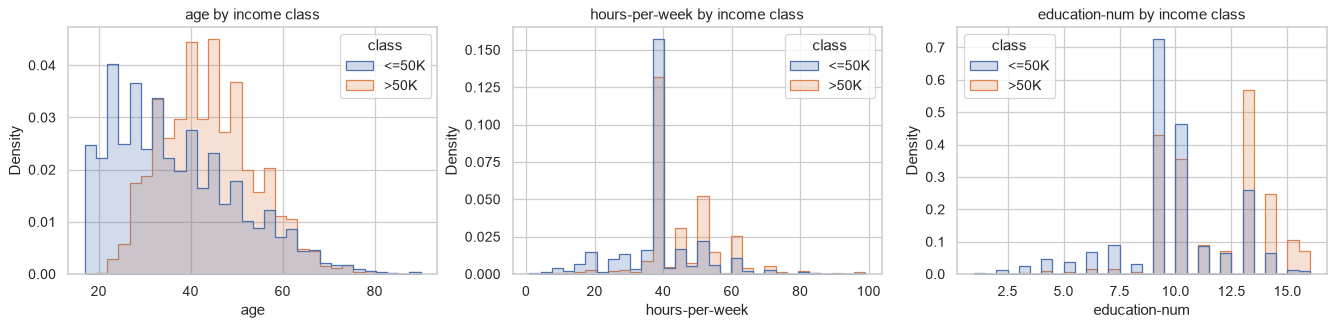

,skewness,excess kurtosis,"median, income <=50K","median, income >50K"
age,0.53,-0.16,34.0,43.0
fnlwgt,1.45,6.18,178952.5,176775.5
education-num,-0.31,0.64,9.0,12.0
capital-gain,11.79,150.15,0.0,0.0
capital-loss,4.52,19.36,0.0,0.0
hours-per-week,0.34,3.20,40.0,40.0


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col in zip(axes, ["age", "hours-per-week", "education-num"]):
    sns.histplot(data=df, x=col, hue=TARGET, stat="density", common_norm=False, element="step", bins=30, ax=ax)
    ax.set_title(f"{col} by income class")
plt.show()
shape = pd.DataFrame({"skewness": df[NUMERIC].skew(), "excess kurtosis": df[NUMERIC].kurt()}).round(2)
shape["median, income <=50K"] = df[df[TARGET] == "<=50K"][NUMERIC].median()
shape["median, income >50K"] = df[df[TARGET] == ">50K"][NUMERIC].median()
shape

The >50K group is clearly **older** (median 43 vs 34) and **more educated** (median `education-num` 12 vs 9): those histograms are
shifted. For `hours-per-week` the medians are equal (both 40, because so many people work exactly 40 hours), but the whole
distribution of the >50K group sits to the right: its *mean* is about 5 hours higher (see the pivot table in 5.2). Always
look at the plot as well as one summary number. `fnlwgt` barely differs between the classes.

### Correlation analysis
**Pearson** `r` measures *linear* association (-1 to 1); **Spearman** works on ranks and also catches monotone non-linear
relationships. For a numeric attribute vs the 0/1 target, Pearson is the *point-biserial* correlation. For two *categorical*
attributes use **Cramer's V** (0 to 1). Remember: **correlation is not causation**, and one outlier can create or hide a
correlation.

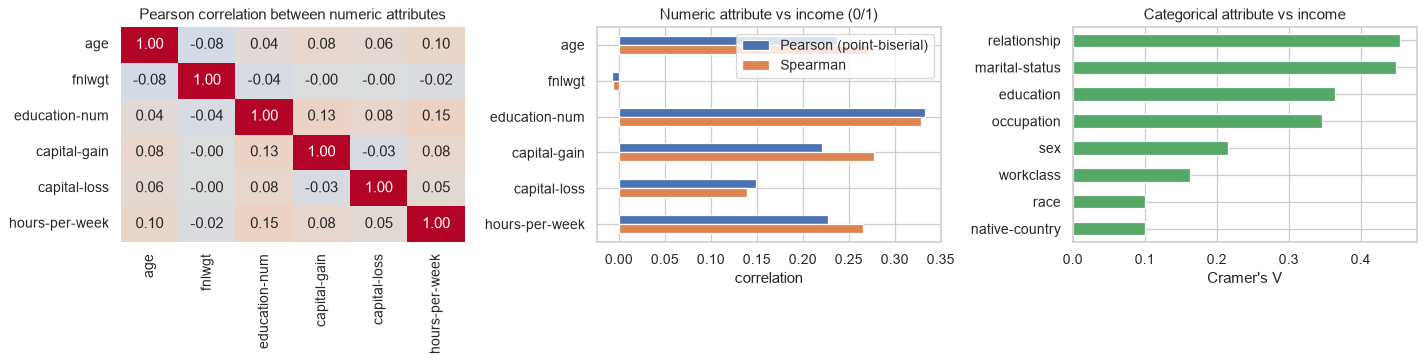

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
Pearson (point-biserial),0.237,-0.007,0.333,0.221,0.149,0.227
Spearman,0.272,-0.006,0.329,0.277,0.139,0.266


Categorical attributes ranked by association with income: {'relationship': 0.455, 'marital-status': 0.449, 'education': 0.364, 'occupation': 0.346, 'sex': 0.216, 'workclass': 0.163, 'native-country': 0.1, 'race': 0.1}


In [9]:
from scipy import stats

y01 = (df[TARGET] == ">50K").astype(int)
def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    return np.sqrt(stats.chi2_contingency(ct, correction=False)[0] / (ct.values.sum() * (min(ct.shape) - 1)))

cats = [c for c in df.columns if c not in NUMERIC and c != TARGET]
num_vs_y = pd.DataFrame({"Pearson (point-biserial)": df[NUMERIC].corrwith(y01), "Spearman": df[NUMERIC].corrwith(y01, method="spearman")}).round(3)
cat_vs_y = pd.Series({c: cramers_v(df[c], df[TARGET]) for c in cats}, name="Cramer's V with class").sort_values(ascending=False).round(3)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
sns.heatmap(df[NUMERIC].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title("Pearson correlation between numeric attributes")
num_vs_y.plot.barh(ax=axes[1]); axes[1].set(title="Numeric attribute vs income (0/1)", xlabel="correlation"); axes[1].invert_yaxis()
cat_vs_y.sort_values().plot.barh(ax=axes[2], color="C2"); axes[2].set(title="Categorical attribute vs income", xlabel="Cramer's V")
plt.show()
display(num_vs_y.T); print("Categorical attributes ranked by association with income:", cat_vs_y.to_dict())

**Reading the results.** The numeric attributes are only weakly correlated *with each other* (the heatmap is nearly all pale),
so there is little redundancy to remove. Against income, `education-num` (r = 0.33), `age` (0.24), `hours-per-week` (0.23) and
`capital-gain` (0.22) have moderate positive relationships; `fnlwgt` has none (-0.01). Spearman is higher than Pearson for
`capital-gain` (0.28 vs 0.22): the relationship is monotone but not linear (most people have zero gain). Among the categorical
attributes, **relationship and marital status** (Cramer's V about 0.45) are the most associated with income, followed by
`education` (0.36) and `occupation` (0.35), then `sex` (0.22); `workclass`, `native-country` and `race` are weaker (0.10-0.16).
Relationship and marital status are strongly related to *each other* too, a form of redundancy to keep in mind when
selecting features.

### Detecting trends and patterns
A **trend** is how the outcome changes along an ordered attribute; a **pattern** is a combination of attributes that behaves
differently. Plot the *share earning >50K* along `age`, and across education and hours:

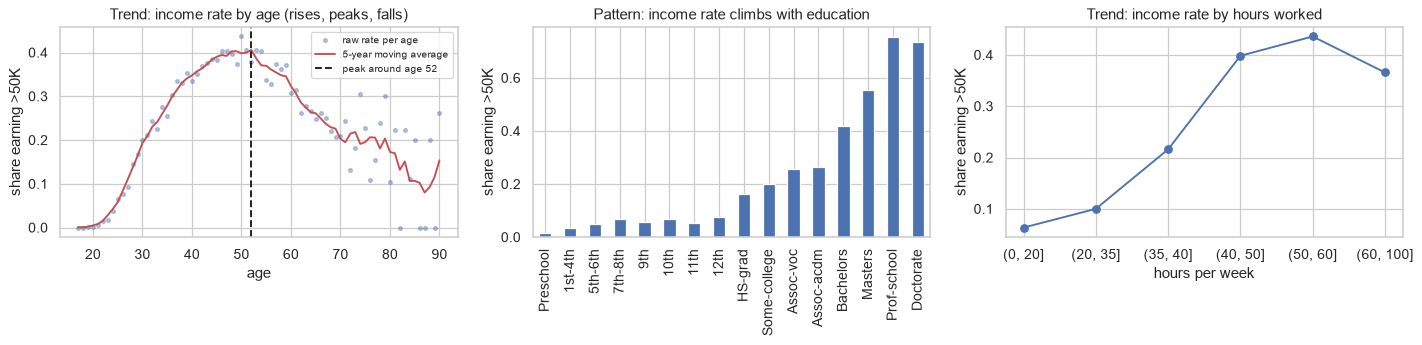

Smoothed income rate peaks around age 52 (41%); education: 1% (lowest level) -> 73% (highest)


In [10]:
rate_age = df.groupby("age")[TARGET].apply(lambda s: (s == ">50K").mean())
n_age = df["age"].value_counts().sort_index()
smooth = rate_age.rolling(5, center=True, min_periods=1).mean()
peak_age = int(smooth[n_age >= 50].idxmax())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(rate_age.index, rate_age.values, ".", alpha=.4, label="raw rate per age"); axes[0].plot(smooth.index, smooth.values, "r", label="5-year moving average")
axes[0].axvline(peak_age, color="k", ls="--", label=f"peak around age {peak_age}")
axes[0].set(title="Trend: income rate by age (rises, peaks, falls)", xlabel="age", ylabel="share earning >50K"); axes[0].legend(fontsize=8)

edu_rate = df.groupby("education", observed=True)[TARGET].apply(lambda s: (s == ">50K").mean())
edu_rate = edu_rate.loc[df.groupby("education", observed=True)["education-num"].first().sort_values().index]
edu_rate.plot.bar(ax=axes[1], color="C0"); axes[1].set(title="Pattern: income rate climbs with education", ylabel="share earning >50K", xlabel="")

hours_rate = df.groupby(pd.cut(df["hours-per-week"], [0, 20, 35, 40, 50, 60, 100]), observed=True)[TARGET].apply(lambda s: (s == ">50K").mean())
hours_rate.plot(marker="o", ax=axes[2]); axes[2].set(title="Trend: income rate by hours worked", ylabel="share earning >50K", xlabel="hours per week")
plt.show()
print(f"Smoothed income rate peaks around age {peak_age} ({smooth[peak_age]:.0%}); education: {edu_rate.iloc[0]:.0%} (lowest level) -> {edu_rate.iloc[-1]:.0%} (highest)")

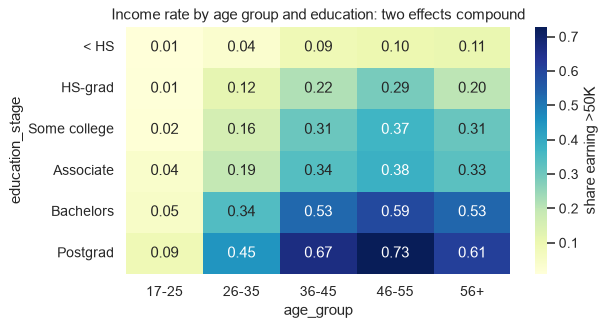

In [11]:
# A pattern across TWO attributes: age group x education stage
tmp = df.assign(age_group=pd.cut(df["age"], [16, 25, 35, 45, 55, 100], labels=["17-25", "26-35", "36-45", "46-55", "56+"]),
                education_stage=pd.cut(df["education-num"], [0, 8, 9, 10, 12, 13, 16], labels=["< HS", "HS-grad", "Some college", "Associate", "Bachelors", "Postgrad"]))
grid = tmp.pivot_table(index="education_stage", columns="age_group", values=TARGET, aggfunc=lambda s: (s == ">50K").mean(), observed=True)
plt.figure(figsize=(7, 3.8))
sns.heatmap(grid, annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={"label": "share earning >50K"})
plt.title("Income rate by age group and education: two effects compound")
plt.show()

## 5.5 Feature engineering

Features are what the model actually sees; better features often beat a fancier model. Three families:

1. **Feature extraction / construction**: create new attributes from existing ones (ratios, flags, bins, aggregates; PCA scores
   from Unit IV are also *extracted* features).
2. **Feature selection**: keep only the useful attributes (less overfitting, faster, easier to explain).
3. **Feature scaling**: put attributes on comparable scales (needed for distance- and gradient-based models).

We work on the training split only and evaluate on the *validation* split (the test set stays untouched until 5.7).

In [12]:
from data import three_way_split
from baseline import build_preprocessor
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

X, y = df.drop(columns=TARGET), df[TARGET]
X_tr, X_va, X_te, y_tr, y_va, y_te = three_way_split(X, y, seed=SEED)
print(f"train {len(X_tr):,} | validation {len(X_va):,} | test {len(X_te):,}")

def add_features(X):
    X = X.copy()
    X["net_capital"] = X["capital-gain"] - X["capital-loss"]
    X["has_gain"] = (X["capital-gain"] > 0).astype(int)
    X["has_loss"] = (X["capital-loss"] > 0).astype(int)
    X["log_gain"] = np.log1p(X["capital-gain"])
    X["age_squared"] = X["age"] ** 2                                   # lets a linear model bend: income peaks mid-career
    X["is_married"] = X["marital-status"].astype(str).str.startswith("Married").astype(int)
    X["long_hours"] = (X["hours-per-week"] > 45).astype(int)
    X["age_group"] = pd.cut(X["age"], [0, 25, 40, 60, 120], labels=["<=25", "26-40", "41-60", "60+"])
    return X

def fit_eval(Xa, ya, Xb, yb, clf):
    pipe = Pipeline([("prep", build_preprocessor(Xa)), ("clf", clf)]).fit(Xa, ya)
    proba = pipe.predict_proba(Xb)[:, list(pipe.classes_).index(">50K")]
    pred = pipe.predict(Xb)
    return {"accuracy": accuracy_score(yb, pred), "F1 (>50K)": f1_score(yb, pred, pos_label=">50K"), "ROC-AUC": roc_auc_score(yb == ">50K", proba)}

rows = {}
for name, clf in {"Logistic regression": LogisticRegression(max_iter=1000, random_state=SEED),
                  "Random Forest (100 trees)": RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)}.items():
    rows[(name, "original 14 features")] = fit_eval(X_tr, y_tr, X_va, y_va, clf)
    rows[(name, "+ 8 engineered features")] = fit_eval(add_features(X_tr), y_tr, add_features(X_va), y_va, clf)
display(pd.DataFrame(rows).T.round(4))

train 31,655 | validation 6,783 | test 6,784


accuracy  F1 (>50K)  \
Logistic regression       original 14 features       0.8420     0.6429   
                          + 8 engineered features    0.8483     0.6621   
Random Forest (100 trees) original 14 features       0.8424     0.6517   
                          + 8 engineered features    0.8399     0.6465   

                                                   ROC-AUC  
Logistic regression       original 14 features      0.9017  
                          + 8 engineered features   0.9069  
Random Forest (100 trees) original 14 features      0.8953  
                          + 8 engineered features   0.8983

**Honest reading.** Engineered features help the *linear* model (it cannot invent a curve or an interaction by itself, so
`age_squared`, `has_gain` and `is_married` give it new information) and change the Random Forest very little (trees can already
split on thresholds and combine attributes). *Feature engineering pays most for simple models.* Always measure on validation
data rather than assume a new feature helps.

### Feature selection
Three kinds of method: **filter** (score each feature on its own, e.g. the ANOVA F-test or mutual information),
**embedded** (the model selects while training: L1-regularised regression zeros out weak coefficients; tree importances), and
**wrapper** (search over subsets by refitting). Below, all scores are computed on the **training split** only.

In [13]:
from sklearn.feature_selection import f_classif, mutual_info_classif, VarianceThreshold

prep = build_preprocessor(X_tr)
Z_tr, Z_va = prep.fit_transform(X_tr), prep.transform(X_va)
Z_tr = Z_tr.toarray() if hasattr(Z_tr, "toarray") else Z_tr
Z_va = Z_va.toarray() if hasattr(Z_va, "toarray") else Z_va
names = np.array([n.split("__", 1)[1] for n in prep.get_feature_names_out()])
is_onehot = ~np.isin(names, NUMERIC)
print(f"{Z_tr.shape[1]} encoded features ({is_onehot.sum()} one-hot + {(~is_onehot).sum()} numeric)")

f_score, _ = f_classif(Z_tr, y_tr)
sub = np.random.default_rng(SEED).choice(len(Z_tr), 10000, replace=False)
mi = mutual_info_classif(Z_tr[sub], y_tr.iloc[sub], discrete_features=is_onehot, random_state=SEED)
l1 = LogisticRegression(C=0.05, l1_ratio=1.0, solver="saga", max_iter=300, random_state=SEED).fit(Z_tr, y_tr)
rf_imp = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1).fit(Z_tr, y_tr).feature_importances_
low_var = (~VarianceThreshold(0.01).fit(Z_tr).get_support()).sum()

scores = {"F-test (filter)": f_score, "mutual information (filter)": mi, "L1 |coefficient| (embedded)": np.abs(l1.coef_[0]), "RF importance (embedded)": rf_imp}
top8 = pd.DataFrame({k: names[np.argsort(-v)][:8] for k, v in scores.items()}, index=range(1, 9)).rename_axis("rank")
print(f"VarianceThreshold(0.01) would drop {low_var} near-constant features; L1 sets {(l1.coef_[0] == 0).sum()} of {len(names)} coefficients exactly to 0.")
top8

104 encoded features (98 one-hot + 6 numeric)


VarianceThreshold(0.01) would drop 48 near-constant features; L1 sets 70 of 104 coefficients exactly to 0.


,F-test (filter),mutual information (filter),L1 |coefficient| (embedded),RF importance (embedded)
rank,,,,
1,marital-status_Married-civ-spouse,marital-status_Married-civ-spouse,capital-gain,fnlwgt
2,relationship_Husband,capital-gain,marital-status_Married-civ-spouse,age
3,education-num,relationship_Husband,relationship_Wife,capital-gain
4,marital-status_Never-married,education-num,occupation_Farming-fishing,hours-per-week
5,age,age,occupation_Exec-managerial,marital-status_Married-civ-spouse
6,hours-per-week,marital-status_Never-married,relationship_Own-child,education-num
7,relationship_Own-child,hours-per-week,education-num,capital-loss
8,capital-gain,capital-loss,occupation_Other-service,relationship_Husband


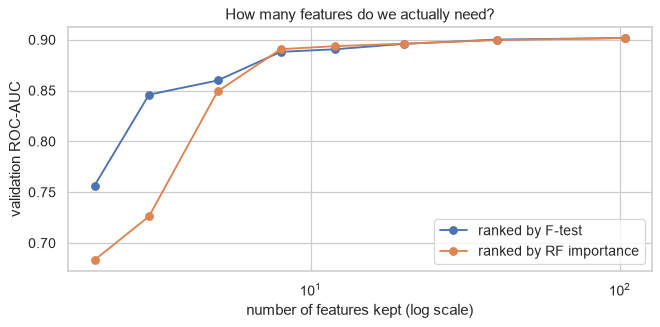

ranked by F-test              ranked by RF importance  \
                    val ROC-AUC val accuracy             val ROC-AUC   
top k features                                                         
2                         0.757        0.752                   0.683   
3                         0.846        0.810                   0.726   
5                         0.860        0.813                   0.849   
8                         0.888        0.833                   0.891   
12                        0.891        0.831                   0.894   
20                        0.896        0.836                   0.896   
40                        0.900        0.839                   0.900   
104                       0.902        0.842                   0.902   

                             
               val accuracy  
top k features               
2                     0.743  
3                     0.783  
5                     0.788  
8                     0.836  
12                    0.837  
20                    0.838  
40                    0.841  
104                   0.842

In [14]:
rank_tables = {}
for key, sc in {"ranked by F-test": f_score, "ranked by RF importance": rf_imp}.items():
    order_ = np.argsort(-sc)
    res = []
    for k in [2, 3, 5, 8, 12, 20, 40, Z_tr.shape[1]]:
        cols = order_[:k]
        m = LogisticRegression(max_iter=1000, random_state=SEED).fit(Z_tr[:, cols], y_tr)
        p = m.predict_proba(Z_va[:, cols])[:, list(m.classes_).index(">50K")]
        res.append({"top k features": k, "val ROC-AUC": roc_auc_score(y_va == ">50K", p), "val accuracy": accuracy_score(y_va, m.predict(Z_va[:, cols]))})
    rank_tables[key] = pd.DataFrame(res).set_index("top k features")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
for key, t in rank_tables.items():
    ax.plot(t.index, t["val ROC-AUC"], "o-", label=key)
ax.set(xscale="log", xlabel="number of features kept (log scale)", ylabel="validation ROC-AUC", title="How many features do we actually need?")
ax.legend(); plt.show()
display(pd.concat(rank_tables, axis=1).round(3))

The curve flattens quickly: 8-12 features already reach a validation AUC of about 0.89, within roughly 0.01 of the full
104-column model (0.902), and 20 features get within about 0.006, so most one-hot columns add little. The two filter methods
agree on the leaders (married-civil-spouse, husband, education, age, hours, capital gain). **Watch the Random Forest column:** its
*impurity* importance ranks `fnlwgt` first, although `fnlwgt` has essentially no relationship with income (r = -0.01).
Impurity importance is biased toward continuous attributes with many distinct values (here 26,741), which offer many
chances to split; the same bias is why the RF-ranked curve starts lower. Prefer filters or *permutation* importance for ranking.
Do selection **inside the training data** (as here) so that the validation score remains an honest estimate.

### Feature scaling: who needs it?
Distance-based models (k-NN) and gradient-based ones (logistic regression, neural nets) are sensitive to scale; tree-based
models are not (they only compare values within one column). Test on the 6 raw numeric attributes, where `fnlwgt` is ~100,000x
larger than `education-num`:

In [15]:
from sklearn.base import clone
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

Xn_tr = X_tr[NUMERIC].sample(10000, random_state=SEED)
yn_tr = y_tr.loc[Xn_tr.index]
res = {}
for name, m in {"k-NN (k=15)": KNeighborsClassifier(15), "Logistic regression": LogisticRegression(max_iter=3000),
                "Random Forest": RandomForestClassifier(100, random_state=SEED, n_jobs=-1)}.items():
    raw = clone(m).fit(Xn_tr, yn_tr).score(X_va[NUMERIC], y_va)
    scaled = Pipeline([("scale", StandardScaler()), ("m", clone(m))]).fit(Xn_tr, yn_tr).score(X_va[NUMERIC], y_va)
    res[name] = {"validation accuracy, raw": raw, "validation accuracy, standardised": scaled, "change": scaled - raw}
display(pd.DataFrame(res).T.round(4))

,"validation accuracy, raw","validation accuracy, standardised",change
k-NN (k=15),0.7806,0.8063,0.0257
Logistic regression,0.8045,0.8045,0.0000
Random Forest,0.8061,0.8055,-0.0006


Standardising raises k-NN accuracy by about 2.6 points, because without it the distance is dominated by `fnlwgt` and the other
attributes are effectively ignored. Logistic regression and the Random Forest do not change in accuracy here (the logistic
regression converges either way when given enough iterations; scaling would still make its coefficients comparable and the
optimiser faster). Remember to **fit the
scaler on training data only** and reuse it; the project does this by putting `StandardScaler` inside a `Pipeline`.

## 5.6 Train-test split and cross-validation

| Set | Purpose | Used |
|---|---|---|
| **Training** (70%) | fit the model's parameters | many times |
| **Validation** (15%) | choose between models / settings / features | many times |
| **Test** (15%) | one final, unbiased estimate | **once** |

`three_way_split` (from `src/data.py`) makes two stratified calls to scikit-learn's `train_test_split`, so every part keeps the
same class balance. `random_state` makes it reproducible.

In [16]:
parts = {"train": y_tr, "validation": y_va, "test": y_te}
tbl = pd.DataFrame({k: {"rows": len(v), "share of data": len(v) / len(df), "share earning >50K": (v == ">50K").mean()} for k, v in parts.items()}).T
display(tbl.round(3))
no_overlap = not (set(X_tr.index) & set(X_va.index)) and not (set(X_tr.index) & set(X_te.index)) and not (set(X_va.index) & set(X_te.index))
print("No row appears in two sets:", no_overlap, "| all rows used:", len(X_tr) + len(X_va) + len(X_te) == len(df))

,rows,share of data,share earning >50K
train,31655.0,0.70,0.248
validation,6783.0,0.15,0.248
test,6784.0,0.15,0.248


No row appears in two sets: True | all rows used: True


A single validation score is **one random draw**: a different split would give a slightly different number. **k-fold
cross-validation** averages over several: split the training data into *k* folds, train on *k-1* of them, score on the held-out
fold, rotate, and report mean +/- standard deviation. *Stratified* k-fold keeps the class balance in each fold. (The project
also uses cross-validation in a different role: *out-of-fold predictions* let a detector judge each row with a model that never
saw it.)

In [17]:
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split

y01_tr = (y_tr == ">50K").astype(int)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
cv = {}
for name, clf in {"Logistic regression": LogisticRegression(max_iter=1000, random_state=SEED),
                  "Random Forest (100 trees)": RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)}.items():
    cv[name] = cross_validate(Pipeline([("prep", build_preprocessor(X_tr)), ("clf", clf)]), X_tr, y01_tr, cv=skf, scoring=scoring)

summary = pd.DataFrame({name: {m: f"{r['test_' + m].mean():.3f} +/- {r['test_' + m].std():.3f}" for m in scoring} for name, r in cv.items()})
print("5-fold stratified cross-validation on the training split (mean +/- std over folds):")
display(summary)

folds = pd.DataFrame({name: r["test_f1"] for name, r in cv.items()}); folds.index = [f"fold {i + 1}" for i in range(5)]
display(folds.round(3).T)

5-fold stratified cross-validation on the training split (mean +/- std over folds):


,Logistic regression,Random Forest (100 trees)
accuracy,0.850 +/- 0.004,0.852 +/- 0.004
precision,0.737 +/- 0.010,0.733 +/- 0.010
recall,0.613 +/- 0.006,0.633 +/- 0.010
f1,0.669 +/- 0.007,0.679 +/- 0.010
roc_auc,0.905 +/- 0.005,0.901 +/- 0.005


,fold 1,fold 2,fold 3,fold 4,fold 5
Logistic regression,0.672,0.682,0.666,0.660,0.666
Random Forest (100 trees),0.678,0.698,0.678,0.671,0.671


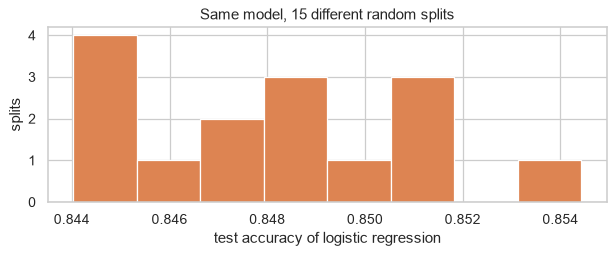

accuracy ranges from 0.8440 to 0.8544 (std 0.0028) just from which rows landed in the test set; so differences smaller than about 0.006 between two models are not trustworthy on one split.


In [18]:
# How much does ONE random split vary?  Repeat a simple 70/30 split 15 times.
accs = []
for i in range(15):
    a, b, ya, yb = train_test_split(X, (y == ">50K").astype(int), test_size=0.3, random_state=i, stratify=y)
    pipe = Pipeline([("prep", build_preprocessor(a)), ("clf", LogisticRegression(max_iter=1000))]).fit(a, ya)
    accs.append(pipe.score(b, yb))
accs = np.array(accs)
plt.figure(figsize=(7, 3)); plt.hist(accs, bins=8, color="C1"); plt.xlabel("test accuracy of logistic regression"); plt.ylabel("splits")
plt.title("Same model, 15 different random splits"); plt.show()
print(f"accuracy ranges from {accs.min():.4f} to {accs.max():.4f} (std {accs.std():.4f}) just from which rows landed in the test set; "
      f"so differences smaller than about {2 * accs.std():.3f} between two models are not trustworthy on one split.")

## 5.7 Model evaluation: confusion matrix, accuracy, precision, recall

The **confusion matrix** counts predictions by actual vs predicted class. Treating `>50K` as the *positive* class:

|  | predicted `<=50K` | predicted `>50K` |
|---|---|---|
| **actually `<=50K`** | TN (true negative) | FP (false positive) |
| **actually `>50K`** | FN (false negative) | TP (true positive) |

- **Accuracy** = (TP + TN) / all: share of all predictions that are right.
- **Precision** = TP / (TP + FP): of those *predicted* positive, how many really are. (Cost of false alarms.)
- **Recall** (sensitivity) = TP / (TP + FN): of the *actual* positives, how many we found. (Cost of misses.)
- **F1** = harmonic mean of precision and recall; **specificity** = TN / (TN + FP).

First, **reproduce the project's Phase-2 baseline** with its own code. The test split is used here for the final report on
two *fixed, pre-chosen* models, the way the research phases use it.

In [19]:
from baseline import build_models, evaluate

models = build_models(build_preprocessor(X_tr), seed=SEED)
for name, pipe in models.items():
    pipe.fit(X_tr, y_tr)
mine = pd.DataFrame({name: evaluate(pipe, X_te, y_te) for name, pipe in models.items()}).T
ref = pd.read_csv(ROOT / "results" / "phase2_clean_baseline.csv").set_index("model")
print("This notebook (test split):"); display(mine.round(4))
print("results/phase2_clean_baseline.csv (the frozen research result):"); display(ref.round(4))
print(f"largest absolute difference over all models and metrics: {(mine - ref[mine.columns]).abs().max().max():.4f}")

This notebook (test split):


,accuracy,precision,recall,f1,roc_auc
logistic_regression,0.8463,0.7279,0.6062,0.6615,0.9047
random_forest,0.8508,0.7253,0.6407,0.6804,0.9032


results/phase2_clean_baseline.csv (the frozen research result):


,accuracy,precision,recall,f1,roc_auc
model,,,,,
logistic_regression,0.8463,0.7279,0.6062,0.6615,0.9047
random_forest,0.8508,0.7253,0.6407,0.6804,0.9032


largest absolute difference over all models and metrics: 0.0000


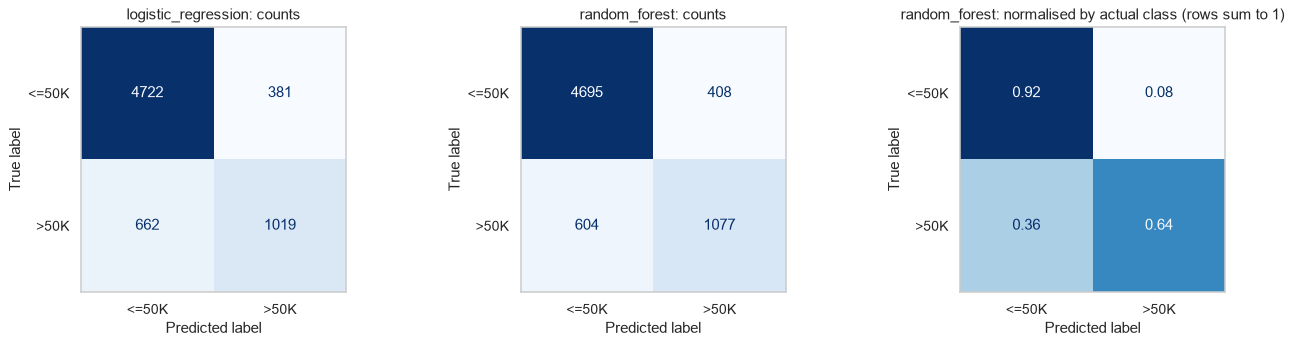

random forest on test: TN=4695  FP=408  FN=604  TP=1077
by hand from the matrix: {'accuracy': np.float64(0.8508), 'precision': np.float64(0.7253), 'recall': np.float64(0.6407), 'F1': np.float64(0.6804), 'specificity': np.float64(0.92)}
sklearn agrees: True

              precision    recall  f1-score   support

       <=50K      0.886     0.920     0.903      5103
        >50K      0.725     0.641     0.680      1681

    accuracy                          0.851      6784
   macro avg      0.806     0.780     0.792      6784
weighted avg      0.846     0.851     0.848      6784



In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, precision_score, recall_score

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pipe) in zip(axes[:2], models.items()):
    ConfusionMatrixDisplay.from_estimator(pipe, X_te, y_te, ax=ax, cmap="Blues", colorbar=False, display_labels=["<=50K", ">50K"])
    ax.set_title(f"{name}: counts"); ax.grid(False)
ConfusionMatrixDisplay.from_estimator(models["random_forest"], X_te, y_te, normalize="true", ax=axes[2], cmap="Blues", colorbar=False,
                                      values_format=".2f", display_labels=["<=50K", ">50K"])
axes[2].set_title("random_forest: normalised by actual class (rows sum to 1)"); axes[2].grid(False)
plt.show()

pred = models["random_forest"].predict(X_te)
tn, fp, fn, tp = confusion_matrix(y_te, pred, labels=["<=50K", ">50K"]).ravel()
by_hand = {"accuracy": (tp + tn) / (tp + tn + fp + fn), "precision": tp / (tp + fp), "recall": tp / (tp + fn),
           "F1": 2 * tp / (2 * tp + fp + fn), "specificity": tn / (tn + fp)}
print(f"random forest on test: TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print("by hand from the matrix:", {k: round(v, 4) for k, v in by_hand.items()})
print("sklearn agrees:", np.isclose(by_hand["precision"], precision_score(y_te, pred, pos_label=">50K")) and np.isclose(by_hand["recall"], recall_score(y_te, pred, pos_label=">50K")))
print(); print(classification_report(y_te, pred, digits=3))

**Accuracy can mislead.** With 75% of people in the `<=50K` class, a "model" that always answers `<=50K` is 75% accurate and
never finds a single high earner. Accuracy must be read together with recall for the class you care about:

In [21]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
dp = dummy.predict(X_te)
cmp_ = pd.DataFrame({
    "always predict <=50K": {"accuracy": accuracy_score(y_te, dp), "precision (>50K)": precision_score(y_te, dp, pos_label=">50K", zero_division=0), "recall (>50K)": recall_score(y_te, dp, pos_label=">50K")},
    "random forest": {"accuracy": accuracy_score(y_te, pred), "precision (>50K)": precision_score(y_te, pred, pos_label=">50K"), "recall (>50K)": recall_score(y_te, pred, pos_label=">50K")},
}).round(3)
cmp_

,always predict <=50K,random forest
accuracy,0.752,0.851
precision (>50K),0.000,0.725
recall (>50K),0.000,0.641


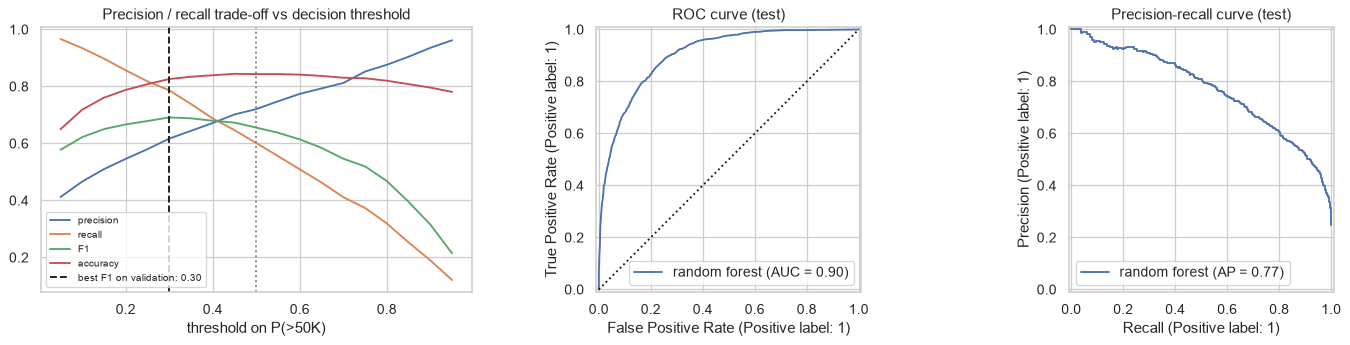

Threshold 0.50 (default): {'precision': 0.723, 'recall': 0.641, 'F1': 0.68, 'accuracy': 0.85}
Threshold 0.30 (picked on validation): {'precision': 0.602, 'recall': 0.802, 'F1': 0.688, 'accuracy': 0.82}


In [22]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

rf = models["random_forest"]
pos = list(rf.classes_).index(">50K")
p_va, p_te = rf.predict_proba(X_va)[:, pos], rf.predict_proba(X_te)[:, pos]
thr = np.linspace(0.05, 0.95, 19)

def at(threshold, y_true, p):
    pr = np.where(p >= threshold, ">50K", "<=50K")
    return {"precision": precision_score(y_true, pr, pos_label=">50K", zero_division=0), "recall": recall_score(y_true, pr, pos_label=">50K"),
            "F1": f1_score(y_true, pr, pos_label=">50K"), "accuracy": accuracy_score(y_true, pr)}

curve = pd.DataFrame([at(t, y_va, p_va) for t in thr], index=thr)
best_thr = curve["F1"].idxmax()                  # chosen on VALIDATION data, then reported once on the test data

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
curve.plot(ax=axes[0]); axes[0].axvline(0.5, color="grey", ls=":"); axes[0].axvline(best_thr, color="k", ls="--", label=f"best F1 on validation: {best_thr:.2f}")
axes[0].set(title="Precision / recall trade-off vs decision threshold", xlabel="threshold on P(>50K)"); axes[0].legend(fontsize=8)
RocCurveDisplay.from_predictions(y_te == ">50K", p_te, ax=axes[1], name="random forest"); axes[1].plot([0, 1], [0, 1], "k:"); axes[1].set_title("ROC curve (test)")
PrecisionRecallDisplay.from_predictions(y_te == ">50K", p_te, ax=axes[2], name="random forest"); axes[2].set_title("Precision-recall curve (test)")
plt.show()
print("Threshold 0.50 (default):", {k: round(v, 3) for k, v in at(0.5, y_te, p_te).items()})
print(f"Threshold {best_thr:.2f} (picked on validation):", {k: round(v, 3) for k, v in at(best_thr, y_te, p_te).items()})

Lowering the threshold finds more high earners (higher recall) at the price of more false alarms (lower precision), and
vice-versa; there is no free lunch, only a choice that depends on the cost of each kind of error. The threshold was chosen on
the **validation** set and only *then* reported on the test set, which keeps the test result honest. **ROC-AUC** summarises the
whole curve in one number independent of any threshold; on imbalanced targets that threshold-free view is more trustworthy than F1
(a finding the project's second-dataset validation made as well).